<a href="https://colab.research.google.com/github/ja2faded/L01-cv/blob/main/L1Group3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Computer Vision

Let's do some very basic computer vision. We're going to import the MNIST handwritten digits data and $k$NN to predict values (i.e. "see/read").

1. To load the data, run the following code in a chunk:
```
import pickle
with open('data/minst.pkl', 'rb') as f:
    data = pickle.load(f)
X_train, y_train = data['X_train'], data['y_train']
X_test, y_test = data['X_test'], data['y_test']
```
The `y_test` and `y_train` vectors, for each index `i`, tell you want number is written in the corresponding index in `X_train[i]` and `X_test[i]`. The value of `X_train[i]` and `X_test[i]`, however, is a 28$\times$28 array whose entries contain values between 0 and 256. Each element of the matrix is essentially a "pixel" and the matrix encodes a representation of a number. To visualize this, run the following code to see the first ten numbers:
```
import matplotlib.pyplot as plt
import numpy as np
np.set_printoptions(edgeitems=30, linewidth=100000)
for i in range(5):
    print(y_test[i],'\n') # Print the label
    print(X_test[i],'\n') # Print the matrix of values
    plt.contourf(np.rot90(X_test[i].transpose())) # Make a contour plot of the matrix values
    plt.show()
```
OK, those are the data: Labels attached to handwritten digits encoded as a matrix.

2. What is the shape of `X_train` and `X_test`? What is the shape of `X_train[i]` and `X_test[i]` for each index `i`? What is the shape of `y_train` and `y_test`?
3. Use Numpy's `.reshape()` method to covert the training and testing data from a matrix into an vector of features. So, `X_test[index].reshape((1,784))` will convert the $index$-th element of `X_test` into a $28\times 28=784$-length row vector of values, rather than a matrix. Turn `X_train` into an $N \times 784$ matrix $X$ that is suitable for scikit-learn's kNN classifier where $N$ is the number of observations and $784=28*28$ (you could use, for example, a `for` loop).
4. Use the reshaped `X_test` and `y_test` data to create a $k$-nearest neighbor classifier of digit. What is the optimal number of neighbors $k$? If you can't determine this, play around with different values of $k$ for your classifier.
5. For the optimal number of neighbors, how well does your predictor perform on the test set? Report the accuracy, compute a confusion matrix, and explain your findings.
6. For your confusion matrix, which mistakes are most likely? Do you find any interesting patterns?
7. So, this is how computers "see." They convert an image into a matrix of values, that matrix becomes a vector in a dataset, and then we deploy ML tools on it as if it was any other kind of tabular data. To make sure you follow this, invent a way to represent a color photo in matrix form, and then describe how you could convert it into tabular data. (Hint: RGB color codes provide a method of encoding a numeric value that represents a color.)

---

## *Phase 1: Solution without AI

Complete all questions in the following cells without generative AI. Then commit and push the
notebook before beginning Phase 2.

**Declaration:** I completed this version without generative AI.

**Student(s):** Jackson Gayeski, Derek Hatherley, Will Morales, Abdullah Rana

**Date:** November 4th, 2026

In [18]:
import pickle
with open('data/minst.pkl', 'rb') as f:
    data = pickle.load(f)
X_train, y_train = data['X_train'], data['y_train']
X_test, y_test = data['X_test'], data['y_test']

7 

[[  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0  84 185 159 151  60  36   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0 222 254 254 254 254 241 198 198 198 198 198 198 19

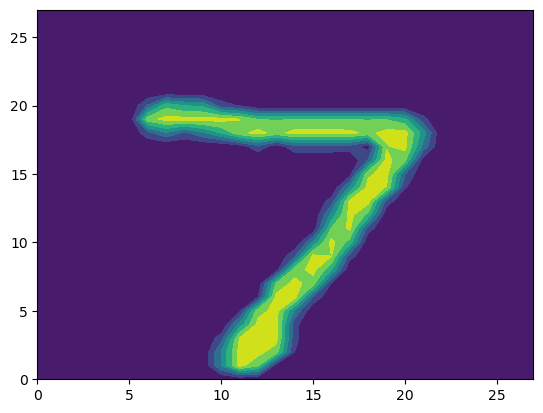

2 

[[  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0 116 125 171 255 255 150  93   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0 169 253 253 253 253 253 253 218  30   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0 169 253 253 253 213 142 176 253 253 122   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0  52 250 253 210  32  12   0   6 206 253 140   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0  77 251 210  25   0   0   0 122 248 253  65   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0  31  18   0   0   0   0 209 253 253  65   

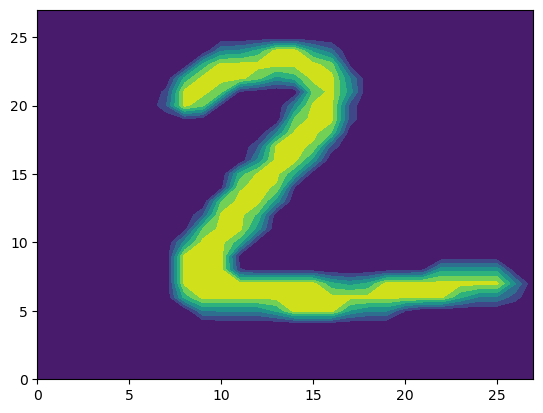

1 

[[  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0  38 254 109   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0  87 252  82   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0 135 241   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0  45 244 150   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0  84 254  63   

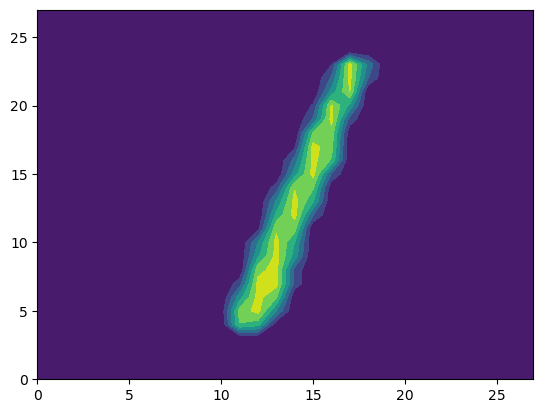

0 

[[  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0  11 150 253 202  31   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0  37 251 251 253 107   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0  21 197 251 251 253 107   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0 110 190 251 251 251 253 169 109  62   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0 253 251 251 251 251 253 251 251 22

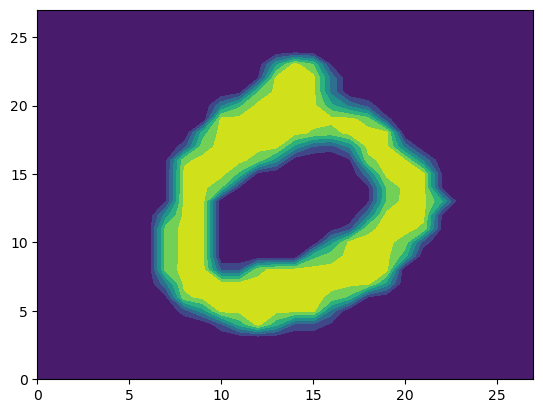

4 

[[  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0  50 224   0   0   0   0   0   0   0  70  29   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0 121 231   0   0   0   0   0   0   0 148 168   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   4 195 231   0   0   0   0   0   0   0  96 210  11   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0  69 252 134   0   0   0   0   0   0   

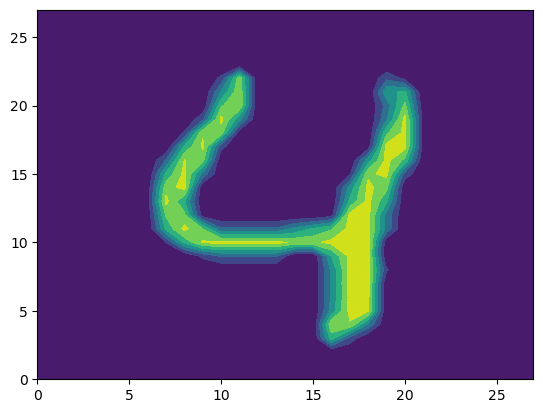

In [19]:
import matplotlib.pyplot as plt
import numpy as np
np.set_printoptions(edgeitems=30, linewidth=100000)
for i in range(5):
    print(y_test[i],'\n') # Print the label
    print(X_test[i],'\n') # Print the matrix of values
    plt.contourf(np.rot90(X_test[i].transpose())) # Make a contour plot of the matrix values
    plt.show()



In [20]:
#q2
print('X_train: ', X_train.shape)
print('X_test: ', X_test.shape)
print('X_train[i]: ', X_train[0].shape)
print('X_test[i]: ', X_test[0].shape)
print('y_train: ', y_train.shape)
print('y_test: ', y_test.shape)

X_train:  (60000, 28, 28)
X_test:  (10000, 28, 28)
X_train[i]:  (28, 28)
X_test[i]:  (28, 28)
y_train:  (60000,)
y_test:  (10000,)


In [21]:
#q3
train_rows = []
for i in range(len(X_train)):
  train_rows.append(X_train[i].reshape(784))
X_train_flat = np.array(train_rows)

test_rows = []
for i in range(len(X_test)):
  test_rows.append(X_test[i].reshape(784))
X_test_flat = np.array(test_rows)


print("Train dimension before: ", X_train.shape)
print("Train dimensions after: ", X_train_flat.shape)
print("Test dimensions before: ", X_test.shape)
print("Test dimensions after: ", X_test_flat.shape)


Train dimension before:  (60000, 28, 28)
Train dimensions after:  (60000, 784)
Test dimensions before:  (10000, 28, 28)
Test dimensions after:  (10000, 784)


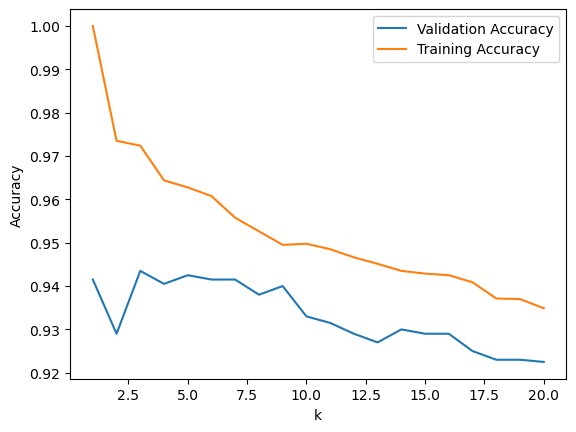


Optimal k: 3
Validation accuracy at optimal k: 0.9435


In [22]:
#q4
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler
from sklearn.neighbors import KNeighborsClassifier

# Runitime was too long with entire set, so using 10,000 random images
eval_X_sub, _, eval_y_sub, _ = train_test_split(X_train_flat, y_train, train_size=10000, random_state=42, stratify=y_train)
# split into training and testing sets
eval_X_tr, eval_X_valid, eval_y_tr, eval_y_valid = train_test_split(eval_X_sub, eval_y_sub, train_size=0.8, random_state=42)

eval_scaler = MinMaxScaler()
eval_X_train_scaled = eval_scaler.fit_transform(eval_X_tr)
eval_X_valid_scaled = eval_scaler.transform(eval_X_valid)

eval_ks = np.arange(1,21) # runtime extremely long for large range
eval_valid_acc = []
eval_train_acc = []
for eval_k in eval_ks:
  eval_candidate = KNeighborsClassifier(n_neighbors=int(eval_k))
  eval_candidate.fit(eval_X_train_scaled, eval_y_tr)
  eval_valid_hat = eval_candidate.predict(eval_X_valid_scaled)
  eval_train_hat = eval_candidate.predict(eval_X_train_scaled)
  eval_valid_acc.append(np.mean(eval_y_valid == eval_valid_hat))
  eval_train_acc.append(np.mean(eval_y_tr == eval_train_hat))

# determine best k value
eval_best_k = int(eval_ks[np.argmax(eval_valid_acc)])

plt.plot(eval_ks, eval_valid_acc, label='Validation Accuracy')
plt.plot(eval_ks, eval_train_acc, label='Training Accuracy')
plt.xlabel('k')
plt.ylabel('Accuracy')
plt.legend()
plt.show()

print()
print(f'Optimal k: {eval_best_k}')
print(f'Validation accuracy at optimal k: {max(eval_valid_acc)}')

# Best k among 1 through 20 on this validation split is 3




In [23]:
#q5
import pandas as pd

scaler = MinMaxScaler()
X_train_scaled = scaler.fit_transform(X_train_flat)
X_test_scaled = scaler.transform(X_test_flat)

#refit for the full training set eith the optimal k from ^
model = KNeighborsClassifier(n_neighbors=eval_best_k)
model.fit(X_train_scaled, y_train)
y_hat = model.predict(X_test_scaled)

test_acc = np.mean(y_test == y_hat)
print(f'Test accuracy at k = {eval_best_k}: {test_acc}')

#confusion matrix
cm = pd.crosstab(y_test, y_hat, rownames=['Actual'], colnames=['Predicted'])
print(cm)

#With k = 3 and the full training set, test accuracy was 0.9705, which is
#higher than the .9435 validation accuracy in Q4. Using all 60,000 training
#images likely helped, but the validation and test images also differ, so the
#increase cannot be attributed entirely to the larger training set. Most
#predictions fall on the main diagonal of the confusion matrix, so errors are rare.

Test accuracy at k = 3: 0.9705
Predicted    0     1    2    3    4    5    6    7    8    9
Actual                                                      
0          974     1    1    0    0    1    2    1    0    0
1            0  1133    2    0    0    0    0    0    0    0
2           10     9  996    2    0    0    0   13    2    0
3            0     2    4  976    1   13    1    7    3    3
4            1     6    0    0  950    0    4    2    0   19
5            6     1    0   11    2  859    5    1    3    4
6            5     3    0    0    3    3  944    0    0    0
7            0    21    5    0    1    0    0  991    0   10
8            8     2    4   16    8   11    3    4  914    4
9            4     5    2    8    9    2    1    8    2  968


In [24]:
#q6

#find most common mistakes
mistakes = []
for i in range(10):
  for j in range(10):
    if i != j:
      mistakes.append((cm.loc[i, j], i, j))
mistakes.sort(reverse=True) #rank the mistakes

print('Most common mistakes (actual, predicted):')
for m in mistakes[:5]:
  print(m[1], 'predicted as', m[2], ':', m[0], 'times')

#recall for each digit
print()
for d in range(10):
  print(d, ':', cm.loc[d, d] / cm.loc[d].sum())
  #The most common mistakes were 7 as 1 (21 times), 4 as 9 (19 times), and 8 as 3
  #(16 times), all digits that look similar when written sloppily. 1 and 0 were
  #easiest (over 99%), and 8 was hardest (93.8%). kNN only compares pixel
  #positions, so digits that share a lot of the same pixels get confused with each other.

Most common mistakes (actual, predicted):
7 predicted as 1 : 21 times
4 predicted as 9 : 19 times
8 predicted as 3 : 16 times
3 predicted as 5 : 13 times
2 predicted as 7 : 13 times

0 : 0.9938775510204082
1 : 0.9982378854625551
2 : 0.9651162790697675
3 : 0.9663366336633663
4 : 0.9674134419551935
5 : 0.9630044843049327
6 : 0.9853862212943633
7 : 0.9640077821011673
8 : 0.9383983572895277
9 : 0.9593657086223984


### Q7

I would represent a color photo with three matrices: one for red, one for green, and one for blue. For an 8-bit RGB image, each value is between 0 and 255 and tells us how much of that color is present at a pixel. For example, `(255, 0, 0)` is red, `(0, 0, 0)` is black, and `(255, 255, 255)` is white. Together, the three matrices form an array with shape `(height, width, 3)`.

To turn this into tabular data, I would read the pixels row by row, keeping the red, green, and blue values together for each pixel. The columns would be `pixel1_R`, `pixel1_G`, `pixel1_B`, `pixel2_R`, and so on. Each photo becomes one row with `height * width * 3` features. A 28 by 28 color photo would therefore have 2,352 features instead of the 784 used for a grayscale MNIST image.

For N photos, I would resize them to the same height and width and flatten each one in the same order, giving a table with shape `(N, height * width * 3)`. The image labels would be kept separately as `y`, just like the digit labels here. We could then train a kNN classifier using the RGB values as features.

## *Phase 2: AI-assisted Revision
Keep Phase 1 frozen.

- **Phase 1 commit SHA ID:** ef7599e831a26cca6cf059cff807a71b0369d00b
- **AI tool and model used:** OpenAI GPT 6.1 Sol

### *Prompts used

### Initial Prompt:

Complete the AI-assisted Phase 2 revision of L1Group3.ipynb, covering Q1–Q7. Use the supplied data and instructions in the noetbook to guide the scope, section order, formatting, etc. Do not edit Phase 1 at all. 

Review the following:
- Q1–Q2: Loading and visualizing the digit images, array shapes and pixel values.
- Q3: Reshaping the training and test images into feature matrices.
- Q4: Building the kNN classifier and selecting the number of neighbors.
- Q5: Reporting test accuracy, constructing the confusion matrix and interpreting performance.
- Q6: Identifying common mistakes and explaining the observed patterns.
- Q7: Representing RGB images numerically and converting them into tabular data.

Document the specific proposed changes. Then provide the complete revised solution, including the required code and written answers. Check that numerical explanations agree with the computed results.
Keep every Phase 1 cell unchanged. Proceed without clarification questions, and avoid analyses or deliverables outside the assignment. Keep Phase 2 concise, yet comprehensive while following the supplied notebook format. 

### Follow Up Prompts:

No additional Phase 2 follow-up prompt was used. 

### *AI-proposed changes


1. **Q1–Q2:** Use the project-relative path `data/minst.pkl`, retain the supplied matrix displays and digit plots, and check the array shapes and observed pixel range.
2. **Q3:** Replace the row-by-row reshape loops with one reshape per dataset, checking that the feature order and every pixel value are unchanged.
3. **Q4:** Retain the original subset, split, scaling and search over 1–20 neighbors. Use the validation curve to select k, remove the unnecessary training-prediction curve, and state the limits of this choice.
4. **Q5:** Refit on the full training set, report the test accuracy and ten-digit confusion matrix, and cross-check the results without attributing the validation/test difference to one proven cause.
5. **Q6:** Rank the off-diagonal mistakes, verify recall for each true digit, and distinguish measured error patterns from possible visual explanations.
6. **Q7:** Retain the RGB representation and explain the common image size, channel order, and one-image-per-row structure needed for a consistent feature table.

### *Evaluation of AI suggestions


These decisions and numerical checks were completed with AI assistance. This revision was executed from a fresh kernel using the supplied data. The improvements concern portability, efficiency and interpretation; they do not establish an accuracy gain.

| Change | Decision | Reason and verification |
|---|---|---|
| 1 | Accept | The relative path loaded the extracted dataset locally. Shapes are `(60000, 28, 28)` and `(10000, 28, 28)`, with matching label vectors; both image sets contain values from 0 to 255. The file must still be present under `data/`, and the kernel must run from the project folder. |
| 2 | Accept | Compared the vectorized results with the original row-by-row reshaping for every image: all values match. The results are `(60000, 784)` and `(10000, 784)`. This simplifies the code without changing the features or predictions. |
| 3 | Accept | The retained 8,000/2,000 training/validation split selects k = 3 at 0.9435. The test set is not used to select k. Training predictions include each image as its own possible neighbor, so that curve is not evidence of performance on new images. A single subset does not establish a universally best k. |
| 4 | Accept | The rerun gives 9,705 correct predictions out of 10,000 (0.9705), and every confusion-matrix entry matches the saved Phase 1 result. Checked the crosstab against `confusion_matrix`, and checked accuracy using both direct matches and the diagonal total. More training images may help, but the evaluation images also differ. |
| 5 | Accept | Verified 7→1: 21, 4→9: 19, and 8→3: 16. Recall calculated from each matrix row agrees with `recall_score`. Digit 1 has the highest recall (99.82%); digit 8 has the lowest (93.84%). These counts alone do not prove that sloppy writing caused the errors. |
| 6 | Accept | Three 28 × 28 channels give 2,352 features per image. A consistent row-major pixel order and RGB order give each column the same meaning across images. Flattening preserves pixel values and positions, but plain kNN does not explicitly model spatial relationships or tolerate shifts automatically. |

### *AI-assisted solution in full
After the evaluation of AI suggestions, incorporate the accepted revisions into your Phase 1 solution and provide the final Phase 2 solution in full in the following cells.

In [25]:
# Your Phase 2 solution to the problem goes here.
# Everything below was provided by the AI agent. 

# Q1. Load and visualize the data

7 

[[  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0  84 185 159 151  60  36   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0 222 254 254 254 254 241 198 198 198 198 198 198 19

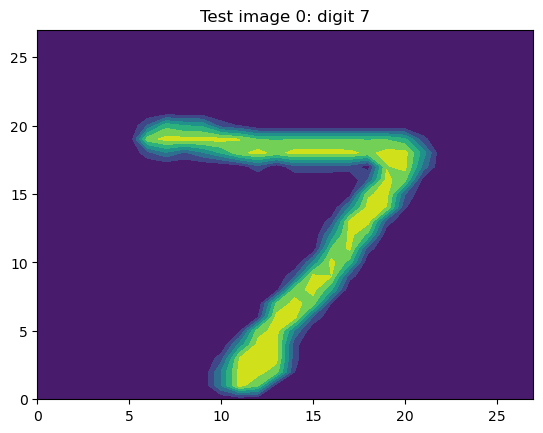

2 

[[  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0 116 125 171 255 255 150  93   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0 169 253 253 253 253 253 253 218  30   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0 169 253 253 253 213 142 176 253 253 122   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0  52 250 253 210  32  12   0   6 206 253 140   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0  77 251 210  25   0   0   0 122 248 253  65   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0  31  18   0   0   0   0 209 253 253  65   

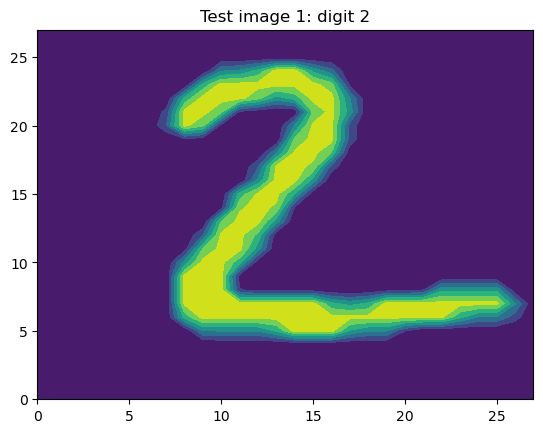

1 

[[  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0  38 254 109   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0  87 252  82   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0 135 241   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0  45 244 150   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0  84 254  63   

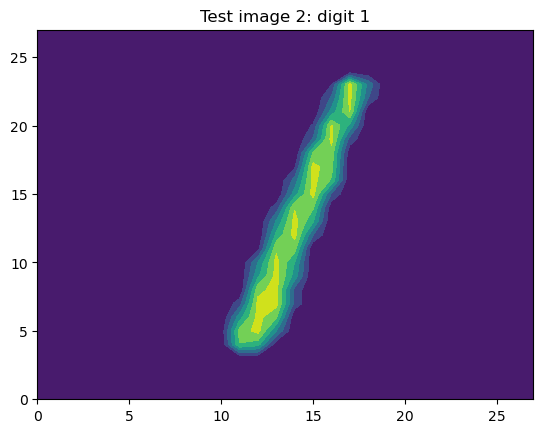

0 

[[  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0  11 150 253 202  31   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0  37 251 251 253 107   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0  21 197 251 251 253 107   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0 110 190 251 251 251 253 169 109  62   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0 253 251 251 251 251 253 251 251 22

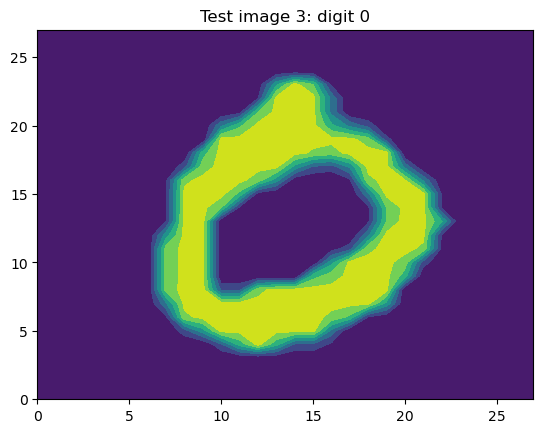

4 

[[  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0  50 224   0   0   0   0   0   0   0  70  29   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0 121 231   0   0   0   0   0   0   0 148 168   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   4 195 231   0   0   0   0   0   0   0  96 210  11   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0  69 252 134   0   0   0   0   0   0   

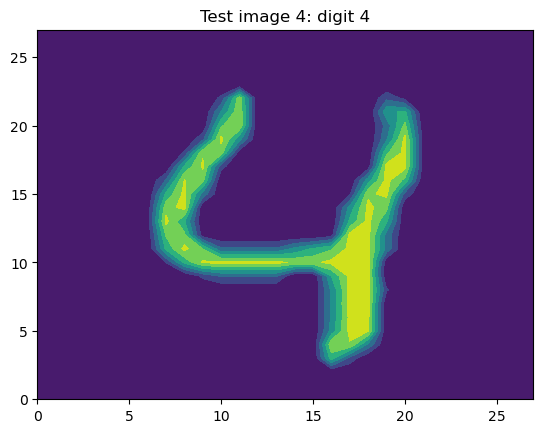

In [26]:
# Q1. Load and visualize the data
import pickle
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, recall_score

with open('data/minst.pkl', 'rb') as f:
    data = pickle.load(f)
X_train, y_train = data['X_train'], data['y_train']
X_test, y_test = data['X_test'], data['y_test']

# Keep matrix displays and contour plots for the first five digits.
np.set_printoptions(edgeitems=30, linewidth=100000)
for i in range(5):
    print(y_test[i], '\n')
    print(X_test[i], '\n')
    plt.contourf(np.rot90(X_test[i].transpose()))
    plt.title(f'Test image {i}: digit {y_test[i]}')
    plt.show()



The first five test labels are 7, 2, 1, 0 and 4, corresponding to the five displayed digits.

# Q2. Shapes of the data

In [27]:
# Q2. Shapes and pixel values
print('X_train:', X_train.shape)
print('X_test:', X_test.shape)
print('X_train[i]:', X_train[0].shape)
print('X_test[i]:', X_test[0].shape)
print('y_train:', y_train.shape)
print('y_test:', y_test.shape)
print('Training pixel range:', X_train.min(), 'to', X_train.max())
print('Test pixel range:', X_test.min(), 'to', X_test.max())
assert X_train.shape == (60000, 28, 28) and X_test.shape == (10000, 28, 28)
assert y_train.shape == (60000,) and y_test.shape == (10000,)
assert 0 <= X_train.min() <= X_train.max() <= 255
assert 0 <= X_test.min() <= X_test.max() <= 255

X_train: (60000, 28, 28)
X_test: (10000, 28, 28)
X_train[i]: (28, 28)
X_test[i]: (28, 28)
y_train: (60000,)
y_test: (10000,)
Training pixel range: 0 to 255
Test pixel range: 0 to 255


There are 60,000 training images and 10,000 test images. `X_train` has shape `(60000, 28, 28)` and `X_test` has shape `(10000, 28, 28)`; each individual image has shape `(28, 28)`. The label vectors have shapes `(60000,)` and `(10000,)`. The observed grayscale values run from 0 to 255 in both image sets.

# Q3. Reshaping images into feature vectors

In [28]:
# Q3. One row per image, with the same pixel order in both sets
X_train_flat = X_train.reshape(len(X_train), -1)
X_test_flat = X_test.reshape(len(X_test), -1)
print('Reshaped training data:', X_train_flat.shape)
print('Reshaped test data:', X_test_flat.shape)
assert X_train_flat.shape == (60000, 784)
assert X_test_flat.shape == (10000, 784)
assert np.array_equal(X_train_flat.reshape(X_train.shape), X_train)
assert np.array_equal(X_test_flat.reshape(X_test.shape), X_test)

Reshaped training data: (60000, 784)
Reshaped test data: (10000, 784)


Reshaping gives a training matrix of shape `(60000, 784)` and a test matrix of shape `(10000, 784)`. Each row is one image, and each column is a fixed pixel position. Reshaping changes the arrangement of the values rather than their values or order. The checks reconstruct both original image arrays exactly.

# Q4. Select the number of neighbors

Training subset: (8000, 784) Validation subset: (2000, 784)
 k  Validation accuracy
 1               0.9415
 2               0.9290
 3               0.9435
 4               0.9405
 5               0.9425
 6               0.9415
 7               0.9415
 8               0.9380
 9               0.9400
10               0.9330
11               0.9315
12               0.9290
13               0.9270
14               0.9300
15               0.9290
16               0.9290
17               0.9250
18               0.9230
19               0.9230
20               0.9225
Best k on this validation split: 3
Best validation accuracy: 0.9435


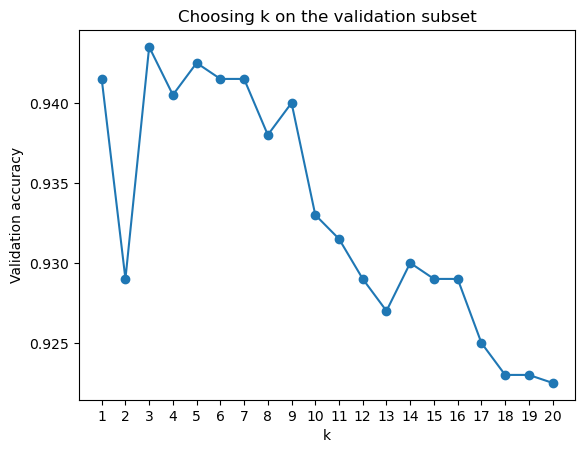

In [29]:
# Q4. Select k using validation data drawn only from the training set
# Retain the Phase 1 subset, split, scaling and candidate values.
eval_X_sub, _, eval_y_sub, _ = train_test_split(
    X_train_flat, y_train, train_size=10000, random_state=42, stratify=y_train)
eval_X_tr, eval_X_valid, eval_y_tr, eval_y_valid = train_test_split(
    eval_X_sub, eval_y_sub, train_size=0.8, random_state=42)

eval_scaler = MinMaxScaler()
eval_X_train_scaled = eval_scaler.fit_transform(eval_X_tr)
eval_X_valid_scaled = eval_scaler.transform(eval_X_valid)

eval_ks = np.arange(1, 21)
eval_valid_acc = []
for eval_k in eval_ks:
    eval_candidate = KNeighborsClassifier(n_neighbors=int(eval_k))
    eval_candidate.fit(eval_X_train_scaled, eval_y_tr)
    eval_valid_hat = eval_candidate.predict(eval_X_valid_scaled)
    eval_valid_acc.append(accuracy_score(eval_y_valid, eval_valid_hat))

# If validation accuracies tie, choose the smallest k among the tied values.
eval_best_k = int(eval_ks[np.argmax(eval_valid_acc)])
print('Training subset:', eval_X_tr.shape, 'Validation subset:', eval_X_valid.shape)
print(pd.DataFrame({'k': eval_ks, 'Validation accuracy': eval_valid_acc}).to_string(index=False))
print(f'Best k on this validation split: {eval_best_k}')
print(f'Best validation accuracy: {max(eval_valid_acc):.4f}')
plt.plot(eval_ks, eval_valid_acc, marker='o')
plt.xticks(eval_ks)
plt.xlabel('k')
plt.ylabel('Validation accuracy')
plt.title('Choosing k on the validation subset')
plt.show()

The best validation accuracy among k = 1 through 20 is **0.9435 at k = 3**. The model is fitted on 8,000 images from the original 10,000-image subset and evaluated on the other 2,000. The scaler is fitted only on those 8,000 training images before transforming validation images. The separate 10,000-image test set is reserved for Q5.

The curve reports validation accuracy rather than accuracy on images used to fit the model. This avoids interpreting memorization as evidence of generalization. The selected k is best for this particular split and candidate range; another subset could select a different value. The original split and scaling are retained so the results remain directly comparable with Phase 1.

# Q5. Classifier performance on the test set

In [30]:
# Q5. Refit on all training images, then evaluate on the separate test set
scaler = MinMaxScaler()
X_train_scaled = scaler.fit_transform(X_train_flat)
X_test_scaled = scaler.transform(X_test_flat)
model = KNeighborsClassifier(n_neighbors=eval_best_k)
model.fit(X_train_scaled, y_train)
y_hat = model.predict(X_test_scaled)
test_acc = accuracy_score(y_test, y_hat)

labels = np.arange(10)
cm = pd.crosstab(y_test, y_hat, rownames=['Actual'], colnames=['Predicted'])
cm = cm.reindex(index=labels, columns=labels, fill_value=0)
print(f'Test accuracy at k = {eval_best_k}: {test_acc:.4f}')
print('Correct predictions:', int(np.sum(y_test == y_hat)), 'of', len(y_test))
print(cm.to_string())

# Check both the matrix entries and the accuracy using separate calculations.
assert np.array_equal(cm.to_numpy(), confusion_matrix(y_test, y_hat, labels=labels))
assert cm.to_numpy().sum() == len(y_test)
assert np.isclose(test_acc, np.trace(cm.to_numpy()) / len(y_test))
assert np.isclose(test_acc, np.mean(y_test == y_hat))

Test accuracy at k = 3: 0.9705
Correct predictions: 9705 of 10000
Predicted    0     1    2    3    4    5    6    7    8    9
Actual                                                      
0          974     1    1    0    0    1    2    1    0    0
1            0  1133    2    0    0    0    0    0    0    0
2           10     9  996    2    0    0    0   13    2    0
3            0     2    4  976    1   13    1    7    3    3
4            1     6    0    0  950    0    4    2    0   19
5            6     1    0   11    2  859    5    1    3    4
6            5     3    0    0    3    3  944    0    0    0
7            0    21    5    0    1    0    0  991    0   10
8            8     2    4   16    8   11    3    4  914    4
9            4     5    2    8    9    2    1    8    2  968


After refitting with **k = 3** on all 60,000 training images, the model correctly predicts **9,705 of 10,000 test digits**, giving accuracy **0.9705 (97.05%)** and 295 errors. The confusion matrix has actual digits in rows and predicted digits in columns. Most observations lie on its main diagonal, indicating correct predictions.

Test accuracy is higher than the 94.35% validation accuracy. The larger training set may help by providing more examples of different handwriting, but the validation and test images also differ, so this comparison does not isolate the effect of training-set size. The scaler is refitted on the full training set and then applied to the test images. Both the test accuracy and the confusion matrix reproduce Phase 1.

# Q6. Analysis of mistakes

In [31]:
# Q6. Rank off-diagonal errors and calculate recall for each true digit
mistakes = []
for i in labels:
    for j in labels:
        if i != j:
            mistakes.append((int(cm.loc[i, j]), int(i), int(j)))
mistakes.sort(reverse=True)
print('\nMost common mistakes (actual, predicted):')
for count, actual, predicted in mistakes[:5]:
    print(actual, 'predicted as', predicted, ':', count, 'times')

recall_by_digit = np.diag(cm.to_numpy()) / cm.sum(axis=1).to_numpy()
print('\nRecall by actual digit:')
print(pd.DataFrame({'Digit': labels, 'Recall': recall_by_digit}).to_string(index=False, float_format=lambda x: f'{x:.4f}'))
assert np.allclose(recall_by_digit, recall_score(y_test, y_hat, labels=labels, average=None))



Most common mistakes (actual, predicted):
7 predicted as 1 : 21 times
4 predicted as 9 : 19 times
8 predicted as 3 : 16 times
3 predicted as 5 : 13 times
2 predicted as 7 : 13 times

Recall by actual digit:
 Digit  Recall
     0  0.9939
     1  0.9982
     2  0.9651
     3  0.9663
     4  0.9674
     5  0.9630
     6  0.9854
     7  0.9640
     8  0.9384
     9  0.9594


The most frequent errors are **7 predicted as 1 (21 times)**, **4 predicted as 9 (19 times)** and **8 predicted as 3 (16 times)**. The next two are 3 predicted as 5 and 2 predicted as 7, each occurring 13 times. These are counts of particular mistakes, rather than error rates adjusted for how often each true digit appears.

Recall divides correct predictions for a digit by the number of test images actually showing that digit. Digit 1 has the highest recall, **99.82%**, followed by digit 0 at **99.39%**. Digit 8 has the lowest recall, **93.84%**. This means the model misses a larger share of actual eights than of any other digit.

Several frequently confused pairs have similar strokes, which is consistent with kNN comparing pixel values at corresponding positions. However, the confusion matrix alone cannot establish why an individual image was misclassified. Flattened-pixel distances can also be sensitive to differences in position and writing style.

# Q7. Representing a color photo as tabular data

I would represent a color photo with three matrices: one for red, one for green, and one for blue. For an 8-bit RGB image, each value is between 0 and 255 and tells us how much of that color is present at a pixel. For example, `(255, 0, 0)` is red, `(0, 0, 0)` is black, and `(255, 255, 255)` is white. Together, the three matrices form an array with shape `(height, width, 3)`.

To turn this into tabular data, I would read the pixels row by row, keeping the red, green, and blue values together for each pixel. The columns would be `pixel1_R`, `pixel1_G`, `pixel1_B`, `pixel2_R`, and so on. Each photo becomes one row with `height * width * 3` features. A 28 by 28 color photo would therefore have 2,352 features instead of the 784 used for a grayscale MNIST image.

For N photos, I would resize them to the same height and width and flatten each one in the same pixel and RGB channel order, giving a table with shape `(N, height * width * 3)`. The image labels would be kept separately as `y`, just like the digit labels here. We could then train a kNN classifier using the RGB values as features. The fixed ordering preserves which position each value belongs to, although ordinary kNN does not explicitly model the relationships between neighboring pixels.

### *Reflection on AI assistance
In your own words without generative AI.

For this assignment, we found the AI-assisted revisions useful in making our original solution easier to run and explaining what the results actually demonstrate. Using a relative data path addressed the loading problem across computers, while replacing the reshaping loops simplified the code without changing the image values. Furthermore, focusing on validation accuracy made the reason for selecting three neighbors clearer.

However, the AI’s earlier review had relied on the saved outputs without rerunning the full notebook. Because of this, its initial assessment did not establish whether the notebook would run in our local environment. Another limitation is that clearer explanations do not necessarily mean a better model. The revised solution reproduced the original test accuracy of 97.05%, so these changes should not be presented as improving predictive performance.

The AI-assisted verification compared the reshaped arrays with the original loop results, checked the confusion matrix using a separate calculation, and confirmed that its diagonal total matched the reported accuracy. These checks supported the numerical results. Before submitting, our group needs to repeat the relevant checks independently and confirm that we understand the changes.

One concern that remains is how much the selected number of neighbors depends on the particular validation subset. Similarly, the confusion matrix identifies common mistakes but cannot establish exactly why they occurred. As such, we would be cautious about assuming the same performance would hold for handwriting with different positioning or styles. 